<span style="font-size: 36px; font-weight: bold; color: #28a745;">Data Preprocessing and Visualization</span>


<font color='#28a745'><b><span style="font-size: 20px;">City Hospital – Data Preprocessing &
Exploratory Analysis</span></b></font> <a class="anchor" id="P0"></a>

**Group 5 Members:**

- **Ana d'Água** (20241773)  
- **Beatriz Calisto** (20241746)  
- **Francisca Teixeira** (20241702)  
- **Margarida Pereira** (20241777)

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Table of Contents

1. **Data Understanding & Cleaning**
   - 1.1 Load and Inspect the Data
   - 1.2 Handle Missing Data
     - 1.2.1 Identifying Missing Values
     - 1.2.2 Handling Missing Values
   - 1.3 Handle Inconsistent Data
     - 1.3.1 Identifying Inconsistent Data (Negative Values, Incorrect Dates)
     - 1.3.2 Avoid conflits in the static features
     - 1.3.3 Correcting data types for optimal performance
   - 1.4 Outlier Detection and Handling
     - 1.4.1 Identifying Outliers 
     - 1.4.2 Removing Outliers

2. **Feature Engineering & ABT Construction**
   - 2.1 Creating the Analytical Base Table (ABT)
   - 2.2 Patient-Level Feature Aggregation
     - 2.2.1 Aggregated Behavior (Consultation Duration, Total Spend)
     - 2.2.2 Satisfaction and Activity Metrics
     - 2.2.3 Dates, Recency, Tenure and Average Interval Between Visits
   - 2.3 Final ABT Structure

3. **Exploratory Visualization & Insights**
   - 3.1 Visualizing Patient Demographics
     - 3.1.1 Age Distribution
     - 3.1.2 Gender and Income Distributions
   - 3.2 Department and Service Usage
     - 3.2.1 Number of Visits per Department and over time
     - 3.2.2 Visits by Age Group and by Gender
   - 3.3 Satisfaction by Department and by patient segment
   - 3.4 Other Insights and Visualizations
     - 3.4.1 Satisfaction vs. Consultation Price
     - 3.4.2 Satisfaction vs. Number of Visits
     - 3.4.3 Correlation Heatmap of Key Features

4. **Exportation of ABT csv files**
---

### **Appendices** (Optional)
- **A.1 Code Snippets**
- **A.2 Data Dictionary**
- **A.3 References**


# <font color='#28a745'>1 Data Understanding & Cleaning

## <font color='#28a745'>1.1 Load and Inspect the Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [3]:
df = pd.read_excel("Project Data.xlsx")
df.head()

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


In [1]:
df.info()

NameError: name 'df' is not defined

In [4]:
# Check the shape of the dataset (rows and columns)
print("Shape of the dataset:", df.shape)

# Summary statistics of numerical columns (mean, std, min, max, etc.)
print("\nSummary statistics of numerical columns:")
df.describe().T

Shape of the dataset: (10008, 16)

Summary statistics of numerical columns:


,count,mean,min,25%,50%,75%,max,std
Patient ID,10008.0,1251.580735,1000.0,1127.0,1252.0,1375.0,1499.0,144.576421
Age,9952.0,50.635651,0.0,23.0,52.0,75.0,195.0,31.185608
Visit Date,10008,2024-03-31 14:53:14.244604160,2024-01-01 00:00:00,2024-02-15 00:00:00,2024-03-31 00:00:00,2024-05-16 00:00:00,2024-06-30 00:00:00,NaN
Consultation Duration,10008.0,67.807654,15.0,41.0,68.0,94.0,600.0,32.447143
Satisfaction Level,10008.0,3.202338,1.0,2.0,3.0,5.0,6.0,1.565507
Approximate Annual Income,9854.0,43402.761315,0.0,31157.75,40876.5,50721.75,11970900.0,268142.006041
Consultation Price,10008.0,187.263022,50.036762,111.316562,159.531115,199.820999,39999.222018,862.86555
Insurance Coverage,9958.0,115.429366,0.0,59.692518,115.938998,165.437958,421.887836,79.337759


In [5]:
# Data types, non-null counts, and memory usage
print("\nData types and non-null counts:")
df.info()


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10008 entries, 0 to 10007
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Patient ID                 10008 non-null  int64         
 1   Age                        9952 non-null   float64       
 2   Gender                     10008 non-null  object        
 3   City of Residence          10008 non-null  object        
 4   Profession                 10008 non-null  object        
 5   Insurance Provider         8098 non-null   object        
 6   Family History             8015 non-null   object        
 7   Education Level            9979 non-null   object        
 8   Marital Status             10008 non-null  object        
 9   Visit Date                 10008 non-null  datetime64[ns]
 10  Department                 10008 non-null  object        
 11  Consultation Duration      10008 n

In [6]:
# Check for duplicate rows in the dataset
duplicate_rows = df[df.duplicated()]

# Display the number of duplicate rows
print(f"Number of duplicate rows: {duplicate_rows.shape[0]}")

# Optionally, you can also view the duplicate rows
print("\nDuplicate Rows:")
duplicate_rows

Number of duplicate rows: 8

Duplicate Rows:


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
510,1330,60.0,Female,Manchester,Artist,NaN,Diabetes,Undergraduate,Married,2024-06-27,Orthopedics,118,1,48263.0,172.566249,NaN
984,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
1770,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
2345,1363,18.0,Male,Glasgow,Student,Provider A,NaN,High school,Single,2024-04-01,Allergology,61,4,0.0,126.757994,101.406395
2712,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
2864,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
8031,1443,16.0,Male,Belfast,Student,Provider D,NaN,High school,Single,2024-05-31,Psychiatry,45,5,0.0,113.077347,113.077347
8715,1306,91.0,Female,London,Retired,Provider D,Hypertension,Master,Widowed,2024-03-11,Orthopedics,32,1,33036.0,221.795387,221.795387


## <font color='#28a745'>1.2 Handle Missing Data

### <font color='#28a745'>1.2.1 Identifying Missing Values

In [7]:
missing_values = df.isnull().sum()
missing_values

Patient ID                      0
Age                            56
Gender                          0
City of Residence               0
Profession                      0
Insurance Provider           1910
Family History               1993
Education Level                29
Marital Status                  0
Visit Date                      0
Department                      0
Consultation Duration           0
Satisfaction Level              0
Approximate Annual Income     154
Consultation Price              0
Insurance Coverage             50
dtype: int64

### <font color='#28a745'>1.2.2 Handling Missing Values

In [8]:
# Preencher os valores ausentes em 'Age' com o valor não ausente para o mesmo Patient ID
for patient_id, group in df.groupby('Patient ID'):
    # Verificar se o paciente tem valores ausentes em 'Age'
    if group['Age'].isnull().any():
        # Pegar o valor válido (não ausente) de 'Age' para o Patient ID
        valid_age = group['Age'].dropna().iloc[0]  # Pegando o primeiro valor válido
        # Preencher os valores ausentes em 'Age' para o paciente com o valor válido
        df.loc[group.index, 'Age'] = df.loc[group.index, 'Age'].fillna(valid_age)

# Verificar se ainda há valores ausentes em 'Age'
print(df['Age'].isnull().sum())

0


In [9]:
# Define the default value if there is no insurance
default_value = "No Insurance"

# Fill missing values in 'Insurance Provider' with valid values from other rows for the same Patient ID
for patient_id, group in df.groupby('Patient ID'):
    # Check if the patient has missing values in 'Insurance Provider'
    if group['Insurance Provider'].isnull().any():
        # Get the first valid (non-null) value from 'Insurance Provider' for the Patient ID
        valid_value = group['Insurance Provider'].dropna().iloc[0] if not group['Insurance Provider'].dropna().empty else default_value
        # Fill the missing values for 'Insurance Provider' with the valid value or the default value
        df.loc[group.index, 'Insurance Provider'] = df.loc[group.index, 'Insurance Provider'].fillna(valid_value)

# Check if there are still missing values in 'Insurance Provider'
print(f"Remaining missing values in 'Insurance Provider': {df['Insurance Provider'].isnull().sum()}")


Remaining missing values in 'Insurance Provider': 0


In [10]:
# Define the default value for missing family history
default_value = "No Disease"

# Fill missing values in 'Family History' with valid values from other rows for the same Patient ID
for patient_id, group in df.groupby('Patient ID'):
    # Check if the patient has missing values in 'Family History'
    if group['Family History'].isnull().any():
        # Get the first valid (non-null) value from 'Family History' for the Patient ID
        valid_value = group['Family History'].dropna().iloc[0] if not group['Family History'].dropna().empty else default_value
        # Fill the missing values for 'Family History' with the valid value or the default value
        df.loc[group.index, 'Family History'] = df.loc[group.index, 'Family History'].fillna(valid_value)

# Check if there are still missing values in 'Family History'
print(f"Remaining missing values in 'Family History': {df['Family History'].isnull().sum()}")


Remaining missing values in 'Family History': 0


In [11]:
# Fill missing values in 'Education Level' with valid values from other rows for the same Patient ID
for patient_id, group in df.groupby('Patient ID'):
    # Check if the patient has missing values in 'Education Level'
    if group['Education Level'].isnull().any():
        # Get the first valid (non-null) value from 'Education Level' for the Patient ID
        valid_value = group['Education Level'].dropna().iloc[0] if not group['Education Level'].dropna().empty else None
        
        # If a valid value exists, fill the missing values for 'Education Level' with the valid value
        if valid_value:
            df.loc[group.index, 'Education Level'] = df.loc[group.index, 'Education Level'].fillna(valid_value)

# Check if there are still missing values in 'Education Level'
print(f"Remaining missing values in 'Education Level': {df['Education Level'].isnull().sum()}")


Remaining missing values in 'Education Level': 0


In [12]:
# Fill missing values in 'Approximate Annual Income' with valid values from other rows for the same Patient ID
for patient_id, group in df.groupby('Patient ID'):
    # Check if the patient has missing values in 'Approximate Annual Income'
    if group['Approximate Annual Income'].isnull().any():
        # Get the first valid (non-null) value from 'Approximate Annual Income' for the Patient ID
        valid_value = group['Approximate Annual Income'].dropna().iloc[0] if not group['Approximate Annual Income'].dropna().empty else None
        # If a valid value exists, fill the missing values for 'Approximate Annual Income' with the valid value
        if valid_value:
            df.loc[group.index, 'Approximate Annual Income'] = df.loc[group.index, 'Approximate Annual Income'].fillna(valid_value)

# Check if there are still missing values in 'Approximate Annual Income'
print(f"Remaining missing values in 'Approximate Annual Income': {df['Approximate Annual Income'].isnull().sum()}")

Remaining missing values in 'Approximate Annual Income': 35


In [13]:
# Step 1: Identify rows with missing 'Approximate Annual Income'
missing_income_data = df[df['Approximate Annual Income'].isnull()]

# Step 2: Check if Age is below 25 and set 'Approximate Annual Income' to 0
for index, row in missing_income_data.iterrows():
    if row['Age'] < 25:
        # Set Approximate Annual Income to 0 if Age is below 25
        df.at[index, 'Approximate Annual Income'] = 0

# Step 3: Check if there are still missing values in 'Approximate Annual Income'
print(f"Remaining missing values in 'Approximate Annual Income': {df['Approximate Annual Income'].isnull().sum()}")


Remaining missing values in 'Approximate Annual Income': 0


In [14]:
# Step 1: Identify rows with missing 'Insurance Coverage'
missing_coverage_data = df[df['Insurance Coverage'].isnull()]

# Step 2: Check 'Insurance Provider' and fill 'Insurance Coverage'
for index, row in missing_coverage_data.iterrows():
    # If 'Insurance Provider' is 'No Insurance', set 'Insurance Coverage' to 0
    if row['Insurance Provider'] == "No Insurance":
        df.at[index, 'Insurance Coverage'] = 0
    else:
        # If 'Insurance Provider' is valid, fill 'Insurance Coverage' from other rows of the same Patient ID
        patient_group = df[df['Patient ID'] == row['Patient ID']]
        valid_coverage = patient_group['Insurance Coverage'].dropna().iloc[0] if not patient_group['Insurance Coverage'].dropna().empty else None
        if valid_coverage is not None:
            df.at[index, 'Insurance Coverage'] = valid_coverage

# Step 3: Check if there are still missing values in 'Insurance Coverage'
print(f"Remaining missing values in 'Insurance Coverage': {df['Insurance Coverage'].isnull().sum()}")


Remaining missing values in 'Insurance Coverage': 0


## <font color='#28a745'>1.3 Handle Inconsistent Data



### <font color='#28a745'>1.3.1 Identifying Inconsistent Data (Negative Values, Incorrect Types)


In [15]:
# Remove duplicates from the dataset
df = df.drop_duplicates()

# Verify that duplicates are removed
print(f"Shape after removing duplicates: {df.shape}")

Shape after removing duplicates: (10000, 16)


In [16]:
# 1.3.1 Identifying Inconsistent Data (Negative Values, Incorrect Dates)

# Check for negative values in columns where they are not expected
negative_values = {
    'Age': df[df['Age'] < 0],
    'Approximate Annual Income': df[df['Approximate Annual Income'] < 0],
    'Consultation Price': df[df['Consultation Price'] < 0],
    'Consultation Duration':df[df['Consultation Duration'] < 0]
}

# Print out any rows with negative values
print("Rows with negative values:")
for column, rows in negative_values.items():
    if not rows.empty:
        print(f"\nNegative values in column '{column}':")
        print(rows)

# Check for incorrect or future dates in the 'Visit Date' column
from datetime import datetime

# Convert 'Visit Date' to datetime format, errors='coerce' will turn invalid dates into NaT (Not a Time)
df['Visit Date'] = pd.to_datetime(df['Visit Date'], errors='coerce')

# Identify rows with incorrect dates (NaT values) or dates in the future
incorrect_dates = df[df['Visit Date'].isna() | (df['Visit Date'] > datetime.now())]

# Print out rows with incorrect or future dates
if not incorrect_dates.empty:
    print("\nRows with incorrect or future dates in 'Visit Date':")
    print(incorrect_dates)
else:
    print("\nNo incorrect or future dates found.")


Rows with negative values:

No incorrect or future dates found.


### <font color='#28a745'>1.3.2 Avoid conflits in the static features

In [17]:
# Columns you want to check
cols_to_check = [
    'Age', 'Gender', 'City of Residence', 'Profession',
    'Education Level', 'Marital Status',
    'Insurance Provider'
]

# Dictionary to store conflicts for each column
conflicts = {}

for col in cols_to_check:
    # Unique values per Patient ID
    temp = (
        df.groupby('Patient ID')[col]
          .apply(lambda x: list(x.dropna().unique()))
          .reset_index()
    )
    
    # Keep IDs with more than one unique value
    temp_conflict = temp[temp[col].apply(lambda x: len(x) > 1)]
    
    if not temp_conflict.empty:
        conflicts[col] = temp_conflict

# Print nicely
for col, result in conflicts.items():
    print(f"\n=== Conflicts in {col} ===")
    print(result)


=== Conflicts in Age ===
     Patient ID            Age
198        1198  [38.0, 138.0]

=== Conflicts in Gender ===
     Patient ID          Gender
50         1050  [Male, Female]
307        1307  [Male, Female]
349        1349  [Male, Female]
447        1447  [Female, Male]
490        1490  [Female, Male]

=== Conflicts in Profession ===
     Patient ID          Profession
488        1488  [Retired, Student]
496        1496  [Retired, Student]

=== Conflicts in Marital Status ===
     Patient ID     Marital Status
140        1140  [Single, Widowed]
322        1322  [Single, Married]
332        1332  [Single, Married]
382        1382  [Single, Widowed]


In [18]:
# 1. AGE conflicts
mode_value = df[df['Patient ID'] == 1198]['Age'].mode().iloc[0]
df.loc[df['Patient ID'] == 1198, 'Age'] = mode_value

# 2. GENDER conflicts
gender_conflicts = [1050, 1307, 1349, 1447, 1490]
for pid in gender_conflicts:
    mode_value = df[df['Patient ID'] == pid]['Gender'].mode().iloc[0]
    df.loc[df['Patient ID'] == pid, 'Gender'] = mode_value

# 3. PROFESSION conflicts (skip 1496, on purpose)
mode_value = df[df['Patient ID'] == 1488]['Profession'].mode().iloc[0]
df.loc[df['Patient ID'] == 1488, 'Profession'] = mode_value

# 4. MARITAL STATUS conflicts
marital_conflicts = [1140, 1322, 1332, 1382]
for pid in marital_conflicts:
    mode_value = df[df['Patient ID'] == pid]['Marital Status'].mode().iloc[0]
    df.loc[df['Patient ID'] == pid, 'Marital Status'] = mode_value

In [19]:
# Patient 1496 is 4 years old and in Pre School, so he is a Student not Retired
# Special case: Patient 1496 → force Profession = "Student"
df.loc[df['Patient ID'] == 1496, 'Profession'] = 'Student'

In [20]:
# Check for remaining conflicts
remaining_conflicts = {}

for col in cols_to_check:
    temp = (
        df.groupby('Patient ID')[col]
          .apply(lambda x: list(x.dropna().unique()))
          .reset_index()
    )
    
    temp_conflict = temp[temp[col].apply(lambda x: len(x) > 1)]
    
    if not temp_conflict.empty:
        remaining_conflicts[col] = temp_conflict

# Print results
if not remaining_conflicts:
    print("No conflicts found")
else:
    print("Remaining conflicts detected:\n")
    for col, conflict_data in remaining_conflicts.items():
        print(f"\n=== Conflicts in {col} ===")
        print(conflict_data)


No conflicts found


### <font color='#28a745'>1.3.3 Correcting data types for optimal performance

In [21]:

# Convert 'Age' to integer (if we don't need decimals)
df['Age'] = df['Age'].astype('int64') # Handle NaNs with 'Int64' (nullable integer)

# Convert categorical columns to 'category' dtype for memory efficiency
categorical_columns = [
    'Gender', 'City of Residence', 'Profession', 
    'Insurance Provider', 'Family History', 
    'Education Level', 'Marital Status', 'Department'
]

df[categorical_columns] = df[categorical_columns].apply(lambda x: x.astype('category'))

# Ensure 'Visit Date' is already datetime64[ns], but just in case, we convert it explicitly
df['Visit Date'] = pd.to_datetime(df['Visit Date'], errors='coerce')

# Check the dtypes after conversion
print(df.dtypes)


Patient ID                            int64
Age                                   int64
Gender                             category
City of Residence                  category
Profession                         category
Insurance Provider                 category
Family History                     category
Education Level                    category
Marital Status                     category
Visit Date                   datetime64[ns]
Department                         category
Consultation Duration                 int64
Satisfaction Level                    int64
Approximate Annual Income           float64
Consultation Price                  float64
Insurance Coverage                  float64
dtype: object


## <font color='#28a745'>1.4 Outlier Detection and Handling

### <font color='#28a745'>1.4.1 Identifying Outliers

In [22]:
import plotly.express as px
import pandas as pd

# Select numerical columns from the DataFrame
numerical_cols = ['Age', 'Consultation Duration', 'Satisfaction Level', 'Approximate Annual Income', 'Consultation Price', 'Insurance Coverage']

# Loop over each numerical column to create individual boxplots
for col in numerical_cols:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile) for IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Calculate the lower and upper bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify outliers based on the IQR rule
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    # Print outliers for this column
    if not outliers.empty:
        print(f"\nOutliers in column '{col}':")
        print(outliers[[col]])
    
    # Create the boxplot
    fig = px.box(df,
                 y=col,  # Only one column per plot
                 title=f"Boxplot of {col} to Identify Outliers using IQR",
                 labels={col: col},  # Labels for the columns
                 color_discrete_sequence=['green'],  # Set the boxplot color to green
                 width=800,  # Width of the plot
                 height=600)  # Height of the plot
    
    # Show the plot
    fig.show()



Outliers in column 'Age':
      Age
4993  195
4994  195
4995  195
4996  195
4997  195
4998  195
4999  195
5000  195
5001  195
5002  195
5003  195
5004  195
5005  195
5006  195
5007  195
5008  195
9884  158
9885  158
9886  158
9887  158
9888  158
9889  158
9890  158
9891  158
9892  158
9893  158
9894  158
9895  158
9896  158
9897  158
9898  158
9899  158
9900  158
9901  158
9902  158
9903  158



Outliers in column 'Consultation Duration':
      Consultation Duration
717                     549
739                     256
3718                    329
3888                    228
5977                    600
6479                    600
7357                    445
7656                    327
7762                    340
7814                    240



Outliers in column 'Approximate Annual Income':
       Approximate Annual Income
170                          0.0
171                          0.0
172                          0.0
173                          0.0
174                          0.0
...                          ...
9961                         0.0
10004                        0.0
10005                        0.0
10006                        0.0
10007                        0.0

[2320 rows x 1 columns]



Outliers in column 'Consultation Price':
      Consultation Price
22            386.790654
23            378.862310
24            354.803404
40            347.838533
56            351.827814
...                  ...
9884          381.222958
9949          360.621240
9962          373.102670
9986          397.916631
9987          389.741871

[240 rows x 1 columns]



Outliers in column 'Insurance Coverage':
      Insurance Coverage
3829          336.201856
3866          347.778538
3870          347.778538
3935          351.281743
3981          358.863268
...                  ...
9755          396.160965
9790          394.756188
9791          392.865397
9884          381.222958
9962          335.792403

[83 rows x 1 columns]


### <font color='#28a745'>1.4.2 Removing Outliers


In [23]:


# Loop through each numerical column to apply clipping based on IQR
for col in numerical_cols:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile) for IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    if col == 'Approximate Annual Income':
        lower_bound = 0
        upper_bound = Q3 + 1.5 * IQR
    else:
        # Calculate the lower and upper bounds for clipping outliers
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
    
    # Apply clipping: values below the lower bound will be set to lower_bound
    # Values above the upper bound will be set to upper_bound
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
    
# Check if the clipping worked by checking some of the data
print(df.head())


   Patient ID  Age  Gender City of Residence Profession Insurance Provider  \
0        1482   65  Female        Birmingham    Retired       No Insurance   
1        1482   65  Female        Birmingham    Retired       No Insurance   
2        1482   65  Female        Birmingham    Retired       No Insurance   
3        1482   65  Female        Birmingham    Retired       No Insurance   
4        1482   65  Female        Birmingham    Retired       No Insurance   

  Family History Education Level Marital Status Visit Date     Department  \
0  Heart Disease          Master       Divorced 2024-02-22  Endocrinology   
1  Heart Disease          Master       Divorced 2024-01-21      Emergency   
2  Heart Disease          Master       Divorced 2024-06-13      Neurology   
3  Heart Disease          Master       Divorced 2024-03-24      Emergency   
4  Heart Disease          Master       Divorced 2024-03-19      Neurology   

   Consultation Duration  Satisfaction Level  Approximate Annual Inc

In [24]:
MAX_AGE = 110
df['Age'] = df['Age'].clip(upper=MAX_AGE)

In [25]:
import plotly.express as px

# List of numerical columns to visualize
numerical_cols = ['Age', 'Consultation Duration', 'Satisfaction Level', 'Approximate Annual Income', 'Consultation Price', 'Insurance Coverage']

# Loop through each numerical column to create individual boxplots
for col in numerical_cols:
    fig = px.box(df, 
                 y=col,  # Only one column per plot
                 title=f"Boxplot of {col} to Visualize Distribution and Outliers",
                 labels={col: col},  # Labels for the columns
                 color_discrete_sequence=['green'],  # Set the boxplot color to green
                 width=800,  # Width of the plot
                 height=600)  # Height of the plot
    fig.show()


In [26]:
import plotly.express as px

# List of categorical columns to visualize
categorical_cols = ['Gender', 'City of Residence', 'Profession', 'Insurance Provider', 'Family History', 'Education Level', 'Marital Status', 'Department']

# Loop through each categorical column to create individual bar plots
for col in categorical_cols:
    fig = px.bar(df, 
                 x=col, 
                 title=f"Bar Plot of {col} to Visualize Frequency",
                 labels={col: col},  # Labels for the columns
                 width=800,  # Width of the plot
                 height=600)  # Height of the plot
    
    # Set the color to green for all bars
    fig.update_traces(marker=dict(color='green'))  # Set the bar color to green
    
    # Show the plot
    fig.show()


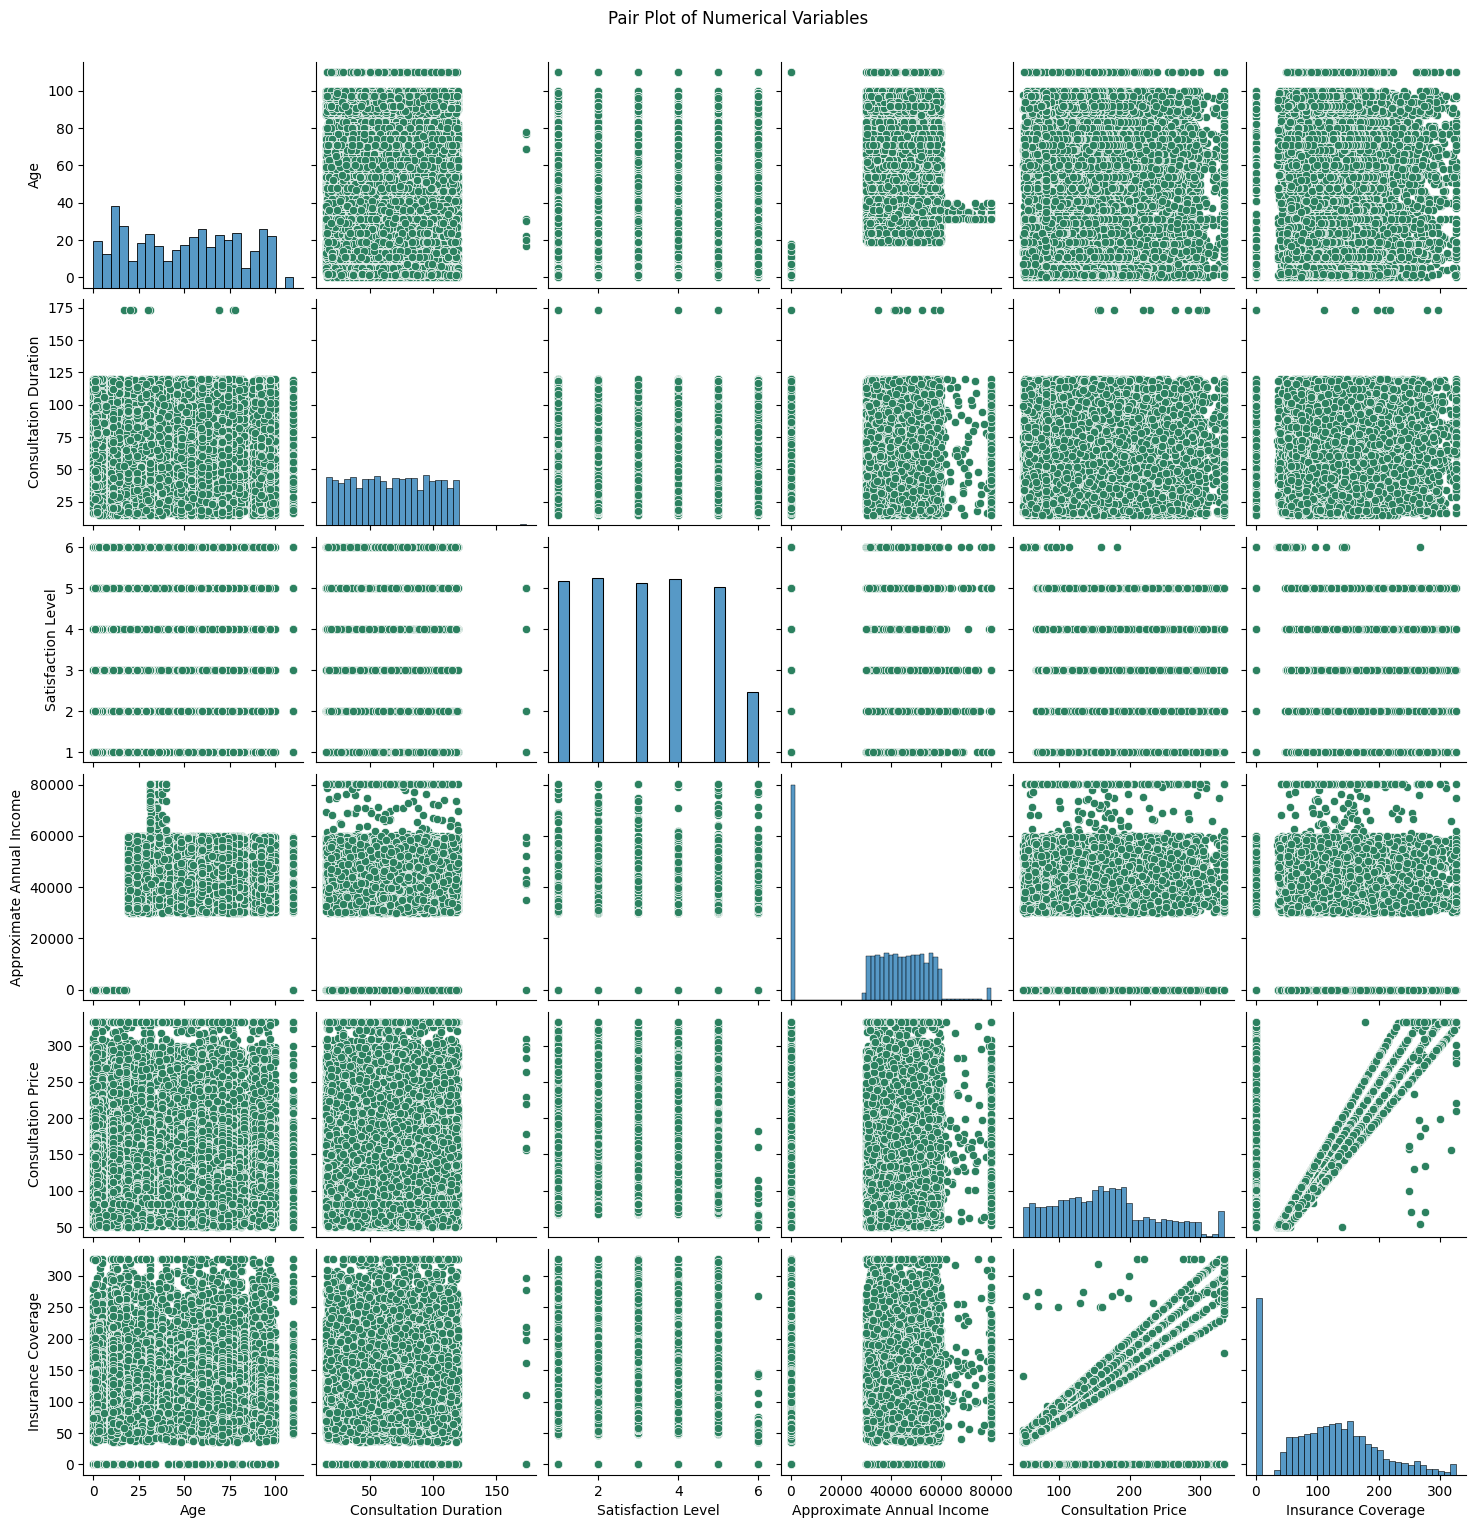

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns for pair plot
numerical_cols_for_pairplot = ['Age', 'Consultation Duration', 'Satisfaction Level', 'Approximate Annual Income', 'Consultation Price', 'Insurance Coverage']

# Create a pair plot with green color
sns.pairplot(df[numerical_cols_for_pairplot], height=2.5, plot_kws={'color':'#2c8160'})

# Add a title to the pair plot
plt.suptitle("Pair Plot of Numerical Variables", y=1.02)

# Show the plot
plt.show()


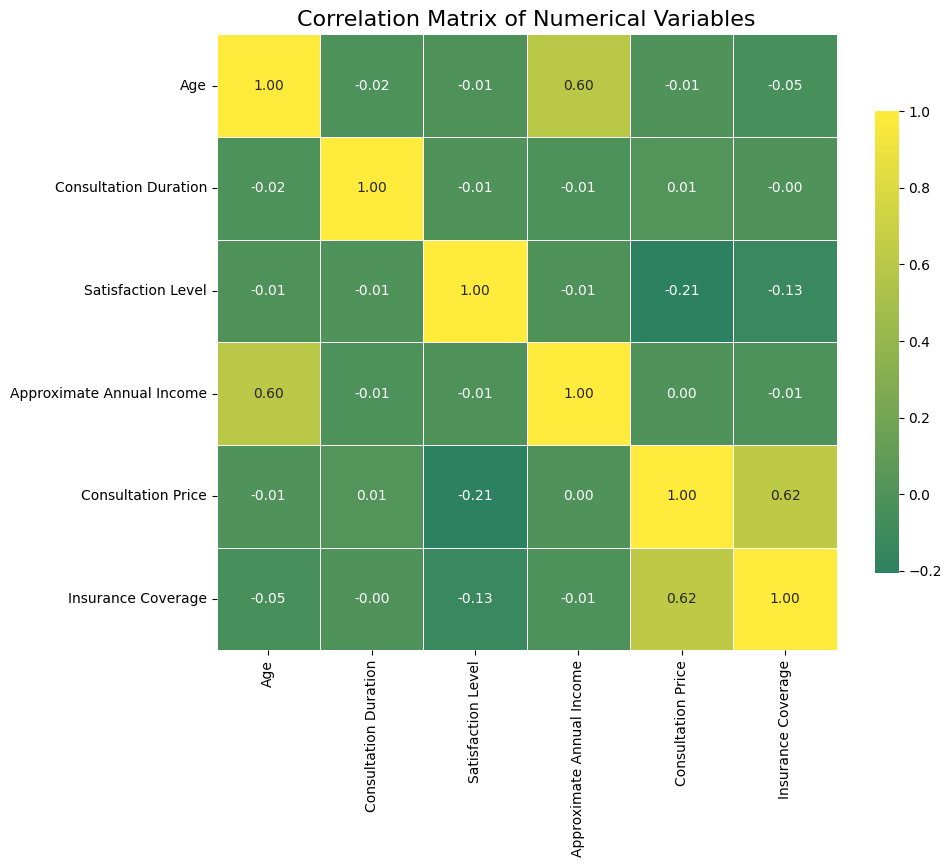

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# List of numerical columns to include in the correlation matrix
numerical_cols = ['Age', 'Consultation Duration', 'Satisfaction Level', 'Approximate Annual Income', 'Consultation Price', 'Insurance Coverage']

# Calculate the correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Create a custom color palette from green to yellow
cmap = mcolors.LinearSegmentedColormap.from_list("green_yellow", ["#2c8160", "#ffeb3b"], N=256)

# Create the heatmap with the custom palette
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap=cmap, fmt='.2f', linewidths=0.5, cbar_kws={'shrink': 0.75})

# Add title
plt.title("Correlation Matrix of Numerical Variables", fontsize=16)

# Show the plot
plt.show()


In [29]:
# Example of histogram for a specific numerical column
fig = px.histogram(df, x='Age', title='Age Distribution', color_discrete_sequence=['green'])
fig.show()


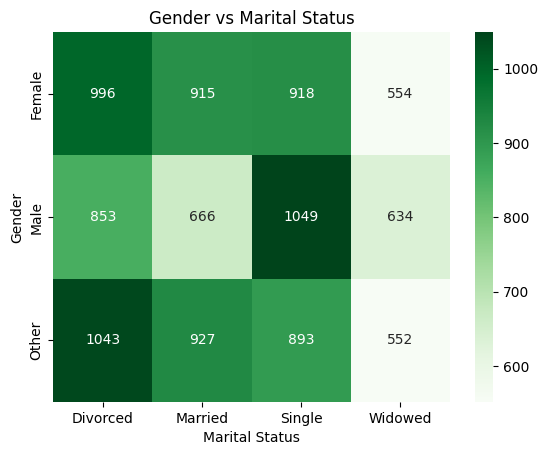

In [30]:
# Example: Heatmap for 'Gender' and 'Marital Status'
gender_marital_status = pd.crosstab(df['Gender'], df['Marital Status'])
sns.heatmap(gender_marital_status, annot=True, cmap='Greens', fmt='d')
plt.title('Gender vs Marital Status')
plt.show()


In [31]:
# Example: Violin plot of 'Consultation Price' by 'Department'
fig = px.violin(df, x='Department', y='Consultation Price', box=True, title='Consultation Price by Department', color_discrete_sequence=['green'])
fig.show()


# <font color='#28a745'>2 Feature Engineering & ABT Construction

## <font color='#28a745'>2.1 Creating the Analytical Base Table (ABT)

In [32]:
static_features = df.groupby('Patient ID').agg({
    'Age': 'last',
    'Gender': 'last',
    'City of Residence': 'last',
    'Profession': 'last',
    'Education Level': 'last',
    'Marital Status': 'last',
    'Insurance Provider': 'last',
    'Approximate Annual Income': 'mean'
}).reset_index()

abt = static_features.copy()

abt.head()

,Patient ID,Age,Gender,City of Residence,Profession,Education Level,Marital Status,Insurance Provider,Approximate Annual Income
0,1000,110,Female,Birmingham,Artist,Undergraduate,Divorced,Provider D,43667.2500
1,1001,55,Male,Liverpool,Lawyer,Undergraduate,Married,Provider C,44214.4375
2,1002,10,Female,Liverpool,Student,Elementary school,Single,Provider C,0.0000
3,1003,91,Male,Manchester,Retired,Master,Married,Provider A,43073.8800
4,1004,11,Male,Glasgow,Student,Middle school/junior high,Single,Provider B,0.0000


## <font color='#28a745'>2.2 Patient-Level Feature Aggregation

### <font color='#28a745'>2.2.1 Aggregated Behavior (Behavioral Attributes)

In [33]:
# 2.2.2 Aggregated Behavior (Consultation Duration, Total Spend)

behavior_features = df.groupby('Patient ID').agg({
    'Consultation Duration': ['sum', 'mean'],
    'Consultation Price': 'sum',
    'Insurance Coverage': 'sum'
}).reset_index().round(2)

# Rename multi-level columns to flat names
behavior_features.columns = [
    'Patient ID',
    'Total_Consultation_Duration',
    'Avg_Consultation_Duration',
    'Total_Consultation_Price',
    'Total_Insurance_Coverage'
]

behavior_features.head()

,Patient ID,Total_Consultation_Duration,Avg_Consultation_Duration,Total_Consultation_Price,Total_Insurance_Coverage
0,1000,1314.0,65.70,3455.43,3448.58
1,1001,968.0,60.50,2396.99,1677.89
2,1002,1279.0,71.06,2919.25,2043.48
3,1003,1535.0,61.40,4441.90,3588.89
4,1004,1629.0,62.65,4486.14,4037.53


### <font color='#28a745'>2.2.2 Satisfaction and Activity Metrics

In [34]:
# 2.2.3 – Satisfaction and Activity Metrics

# Base satisfaction/activity aggregation
satisfaction_activity = df.groupby('Patient ID').agg(
    Mean_Satisfaction=('Satisfaction Level', 'mean'),
    Median_Satisfaction=('Satisfaction Level', 'median'),
    Min_Satisfaction=('Satisfaction Level', 'min'),
    Max_Satisfaction=('Satisfaction Level', 'max'),
    Total_Visits=('Patient ID', 'size'),
    Distinct_Departments=('Department', 'nunique')
).reset_index().round(2)

# Compute most frequent (top) department per patient
top_dept = (
    df.groupby('Patient ID')['Department']
      .agg(lambda x: x.value_counts().idxmax())
      .reset_index()
      .rename(columns={'Department': 'Top_Department'})
)

# Merge into satisfaction_activity
satisfaction_activity = satisfaction_activity.merge(top_dept, on='Patient ID', how='left')

# Preview
satisfaction_activity.head()


,Patient ID,Mean_Satisfaction,Median_Satisfaction,Min_Satisfaction,Max_Satisfaction,Total_Visits,Distinct_Departments,Top_Department
0,1000,2.60,2.5,1,5,20,10,Allergology
1,1001,3.38,4.0,1,6,16,10,ENT
2,1002,3.50,3.0,1,6,18,10,Psychiatry
3,1003,3.32,4.0,1,6,25,11,Psychiatry
4,1004,3.38,4.0,1,6,26,9,General Practice


### <font color='#28a745'>2.2.3 Dates, Recency, Tenure and Average Interval Between Visits

In [35]:
# 2.2.3 Dates, Recency, Tenure and Visit Intervals
# These features describe the patient timeline and activity pattern.

# Convert Visit Date to datetime if not already converted
df["Visit Date"] = pd.to_datetime(df["Visit Date"], errors="coerce")

# Basic date aggregations
recency_features = df.groupby("Patient ID").agg(
    Last_Visit=('Visit Date', 'max'),     # Most recent consultation
    First_Visit=('Visit Date', 'min')     # First recorded consultation
).reset_index()

# Recency: number of days since the last visit (relative to today)
recency_features['Recency_Days'] = (pd.Timestamp.today() - recency_features['Last_Visit']).dt.days

# Tenure: how long the patient has been "active"
recency_features['Tenure_Days'] = (recency_features['Last_Visit'] - recency_features['First_Visit']).dt.days

# Average interval between visits
df_sorted = df.sort_values(['Patient ID', 'Visit Date']).copy()
df_sorted['prev_date'] = df_sorted.groupby('Patient ID')['Visit Date'].shift(1)
df_sorted['gap_days'] = (df_sorted['Visit Date'] - df_sorted['prev_date']).dt.days

avg_gap = df_sorted.groupby('Patient ID')['gap_days'].mean().reset_index(name='Avg_Days_Between_Visits')

# Final recency structure
recency_features = recency_features.merge(avg_gap, on='Patient ID', how='left').round(2)

recency_features.head()


,Patient ID,Last_Visit,First_Visit,Recency_Days,Tenure_Days,Avg_Days_Between_Visits
0,1000,2024-06-27,2024-01-01,521,178,9.37
1,1001,2024-06-27,2024-01-02,521,177,11.80
2,1002,2024-06-23,2024-01-06,525,169,9.94
3,1003,2024-06-29,2024-01-03,519,178,7.42
4,1004,2024-06-28,2024-01-01,520,179,7.16


## <font color='#28a745'>2.3 Final ABT Structure

In [36]:
# 2.3 – Final ABT Structure
# Merge all components of the ABT
abt = (
    static_features
        .merge(behavior_features, on='Patient ID', how='left')
        .merge(satisfaction_activity, on='Patient ID', how='left')
        .merge(recency_features,on='Patient ID', how='left')
)

# Reorder for readability
abt = abt[
    [
        'Patient ID',
        # Static demographic attributes
        'Age', 'Gender', 'City of Residence', 'Profession',
        'Education Level', 'Marital Status', 'Insurance Provider',
        'Approximate Annual Income',

        # Behavioral features
        'Total_Consultation_Duration',
        'Avg_Consultation_Duration',
        'Total_Consultation_Price',
        'Total_Insurance_Coverage',

        # Satisfaction and activity
        'Mean_Satisfaction', 'Median_Satisfaction',
        'Min_Satisfaction', 'Max_Satisfaction',
        'Total_Visits', 'Distinct_Departments',
        'Top_Department',

        # Recency and timeline
        'Last_Visit', 'First_Visit',
        'Recency_Days', 'Tenure_Days',
        'Avg_Days_Between_Visits',
    ]
]

print("Final ABT shape:", abt.shape)
abt.head()


Final ABT shape: (500, 25)


,Patient ID,Age,Gender,City of Residence,Profession,Education Level,Marital Status,Insurance Provider,Approximate Annual Income,Total_Consultation_Duration,...,Min_Satisfaction,Max_Satisfaction,Total_Visits,Distinct_Departments,Top_Department,Last_Visit,First_Visit,Recency_Days,Tenure_Days,Avg_Days_Between_Visits
0,1000,110,Female,Birmingham,Artist,Undergraduate,Divorced,Provider D,43667.2500,1314.0,...,1,5,20,10,Allergology,2024-06-27,2024-01-01,521,178,9.37
1,1001,55,Male,Liverpool,Lawyer,Undergraduate,Married,Provider C,44214.4375,968.0,...,1,6,16,10,ENT,2024-06-27,2024-01-02,521,177,11.80
2,1002,10,Female,Liverpool,Student,Elementary school,Single,Provider C,0.0000,1279.0,...,1,6,18,10,Psychiatry,2024-06-23,2024-01-06,525,169,9.94
3,1003,91,Male,Manchester,Retired,Master,Married,Provider A,43073.8800,1535.0,...,1,6,25,11,Psychiatry,2024-06-29,2024-01-03,519,178,7.42
4,1004,11,Male,Glasgow,Student,Middle school/junior high,Single,Provider B,0.0000,1629.0,...,1,6,26,9,General Practice,2024-06-28,2024-01-01,520,179,7.16


# <font color='#28a745'>3 Exploratory Visualization & Insights

## <font color='#28a745'>3.1 Visualizing Patient Demographics

### <font color='#28a745'>3.1.1 Age Distribution

Age summary statistics:
count    500.00
mean      49.76
std       29.89
min        0.00
25%       23.00
50%       51.00
75%       74.25
max      110.00
Name: Age, dtype: float64


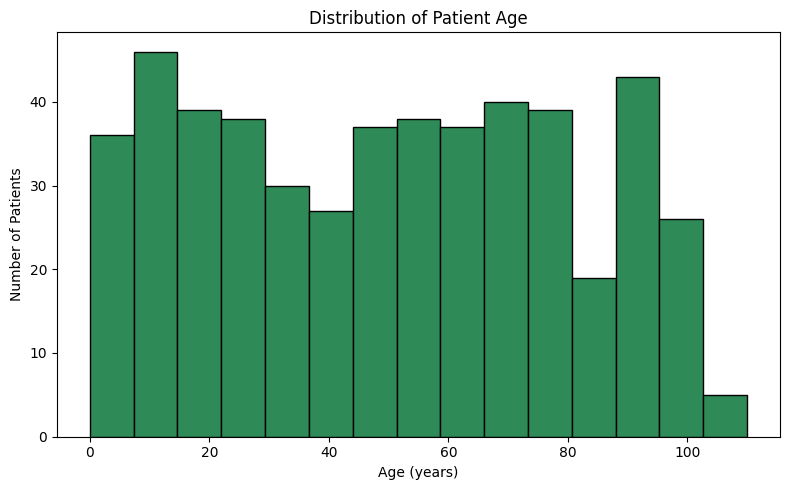


Patient count by age group:
Age_Group
<30      153
30–44     60
45–59     79
60+      202
Name: count, dtype: int64


In [37]:
# 1. Basic checks on Age 
print("Age summary statistics:")
print(abt["Age"].describe().round(2))

# 2. Histogram of Age 
plt.figure(figsize=(8, 5))
plt.hist(abt["Age"], bins=15, edgecolor="black", color='seagreen')
plt.title("Distribution of Patient Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

# 3. Create Age Groups / Bins (for later sections too)
age_bins = [0, 29, 44, 59, 120]
age_labels = ["<30", "30–44", "45–59", "60+"]

abt["Age_Group"] = pd.cut(abt["Age"], bins=age_bins, labels=age_labels, right=True)

print("\nPatient count by age group:")
print(abt["Age_Group"].value_counts().sort_index())


### <font color='#28a745'>3.1.2 Gender and Income Distributions

Gender distribution counts:
Gender
Other     171
Female    169
Male      160
Name: count, dtype: int64


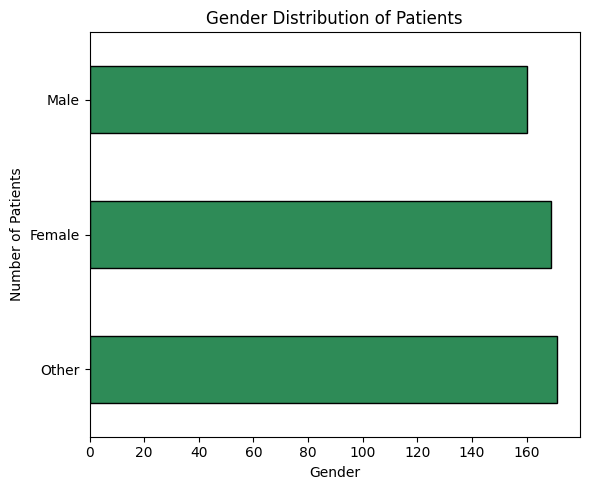

In [38]:
print("Gender distribution counts:")
print(abt["Gender"].value_counts())

plt.figure(figsize=(6, 5))
abt["Gender"].value_counts().plot(kind="barh", edgecolor="black",color='seagreen')
plt.title("Gender Distribution of Patients")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

Income summary statistics:
count      500.00
mean     35518.92
std      19356.30
min          0.00
25%      41060.62
50%      44077.36
75%      45973.51
max      74571.26
Name: Approximate Annual Income, dtype: float64


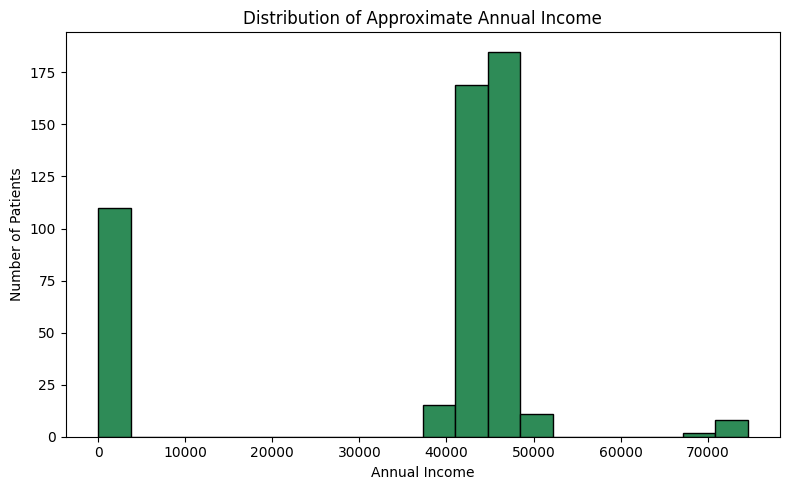

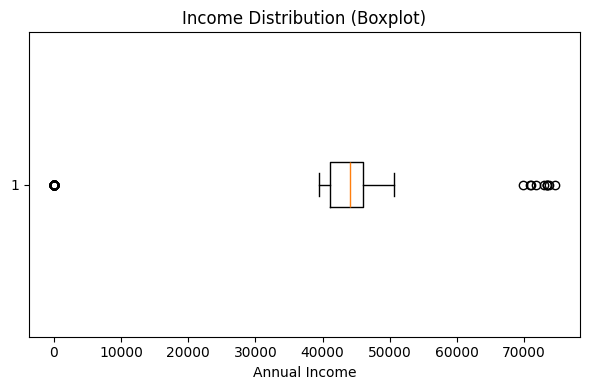

In [39]:
print("Income summary statistics:")
print(abt['Approximate Annual Income'].describe().round(2))

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(abt['Approximate Annual Income'], bins=20, edgecolor="black",color='seagreen')
plt.title("Distribution of Approximate Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

# Boxplot (to visualize skewness)
plt.figure(figsize=(6, 4))
plt.boxplot(abt['Approximate Annual Income'], vert=False)

plt.title("Income Distribution (Boxplot)")
plt.xlabel("Annual Income")
plt.tight_layout()
plt.show()


## <font color='#28a745'>3.2 Department and Service Usage

### <font color='#28a745'>3.2.1 Number of Visits per Department and over time

Number of visits per department:
Department
Psychiatry          1359
General Practice    1331
Gastroenterology     696
Endocrinology        690
Neurology            690
Emergency            682
Rheumatology         678
Allergology          672
Dermatology          661
ENT                  653
Pulmonology          653
Cardiology           642
Orthopedics          593
Name: count, dtype: int64


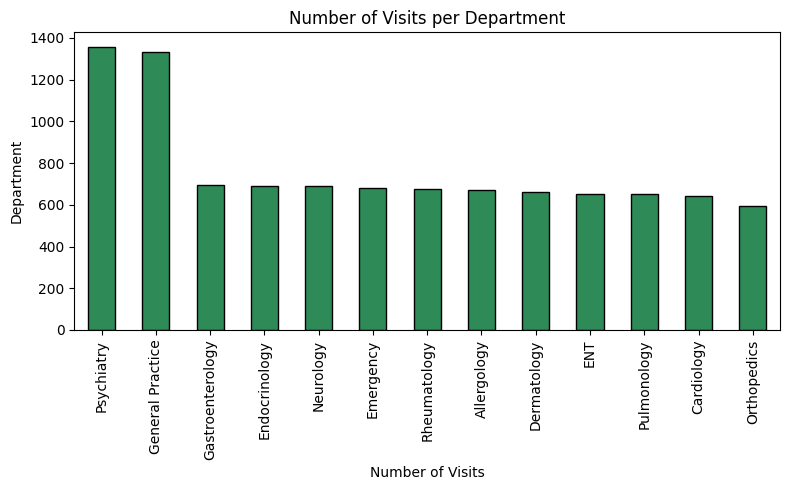

In [40]:
# Count visits per department
dept_counts = df["Department"].value_counts()

print("Number of visits per department:")
print(dept_counts)

# Plot
plt.figure(figsize=(8, 5))
dept_counts.plot(kind="bar", edgecolor="black",color='seagreen')
plt.title("Number of Visits per Department")
plt.xlabel("Number of Visits")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


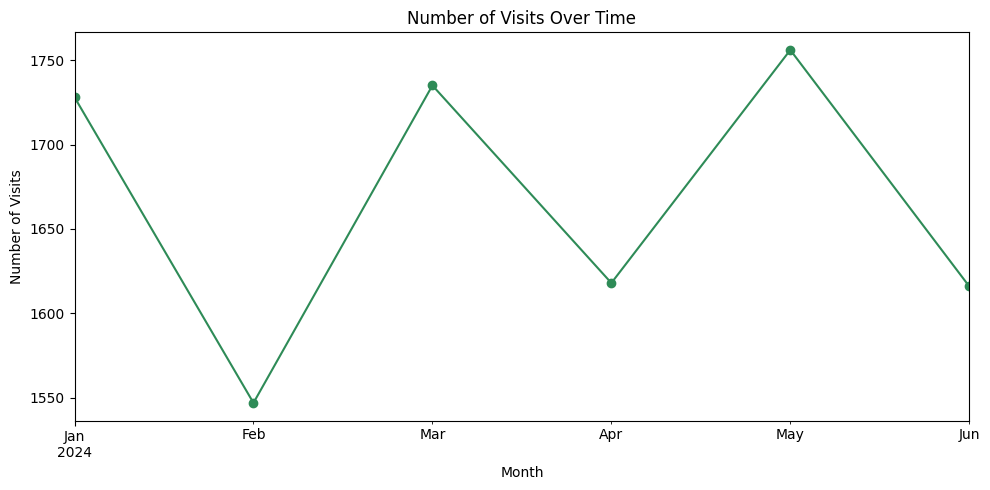

In [41]:
# Number of Visits Over Time

# Count visits per month
visits_over_time = df.groupby(df["Visit Date"].dt.to_period("M")).size()

plt.figure(figsize=(10, 5))
visits_over_time.plot(marker="o", color="seagreen")
plt.title("Number of Visits Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Visits")
plt.tight_layout()
plt.show()

### <font color='#28a745'>3.2.2 Visits by Age Group and by Gender

In [42]:
# Create age groups directly in df
age_bins = [0, 29, 44, 59, 120]
age_labels = ["<30", "30–44", "45–59", "60+"]

df["Age_Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=True)

df.head()

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage,Age_Group
0,1482,65,Female,Birmingham,Retired,No Insurance,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110.0,2,38839.0,293.014042,0.0,60+
1,1482,65,Female,Birmingham,Retired,No Insurance,Heart Disease,Master,Divorced,2024-01-21,Emergency,76.0,4,52219.0,287.208982,0.0,60+
2,1482,65,Female,Birmingham,Retired,No Insurance,Heart Disease,Master,Divorced,2024-06-13,Neurology,17.0,5,41491.0,241.254507,0.0,60+
3,1482,65,Female,Birmingham,Retired,No Insurance,Heart Disease,Master,Divorced,2024-03-24,Emergency,15.0,3,34944.0,221.177483,0.0,60+
4,1482,65,Female,Birmingham,Retired,No Insurance,Heart Disease,Master,Divorced,2024-03-19,Neurology,99.0,1,39248.0,219.743794,0.0,60+


Visits by Department and Age Group:
Age_Group         <30  30–44  45–59  60+
Department                              
Allergology       192     74    104  292
Cardiology        192     74    100  270
Dermatology       200     72     96  280
ENT               188     92     92  271
Emergency         199     89    109  277
Endocrinology     205     78    111  286
Gastroenterology  216     83     93  294
General Practice  409    155    188  562
Neurology         201     81    122  272
Orthopedics       196     66     90  231
Psychiatry        384    193    219  545
Pulmonology       170     64     99  310
Rheumatology      211     86     97  276


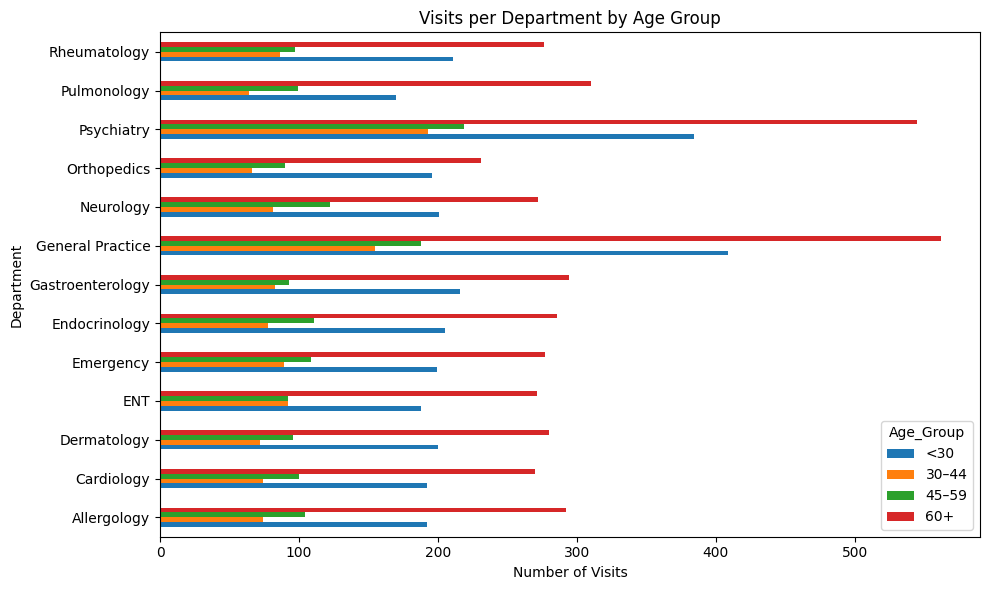

In [43]:
# Count visits by department and age group
dept_age = df.groupby(["Department", "Age_Group"]).size().unstack(fill_value=0)

print("Visits by Department and Age Group:")
print(dept_age)

# Plot
dept_age.plot(kind="barh", figsize=(10, 6))
plt.title("Visits per Department by Age Group")
plt.xlabel("Number of Visits")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


Visits by Department and Gender:
Gender            Female  Male  Other
Department                           
Allergology          230   217    225
Cardiology           218   200    224
Dermatology          225   208    228
ENT                  227   199    227
Emergency            211   220    251
Endocrinology        213   239    238
Gastroenterology     232   208    256
General Practice     467   440    424
Neurology            201   227    262
Orthopedics          198   191    204
Psychiatry           487   443    429
Pulmonology          227   211    215
Rheumatology         247   199    232


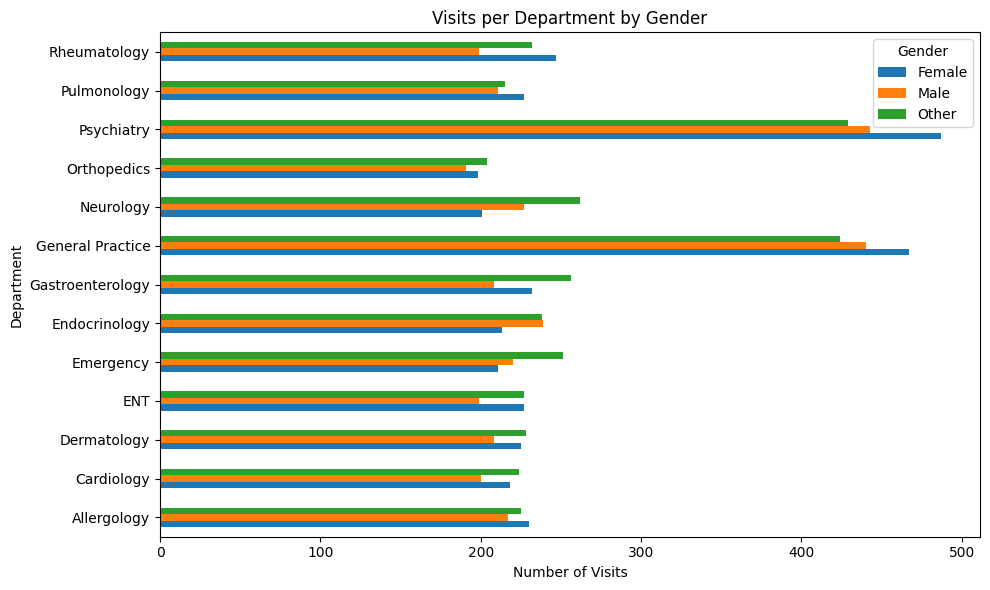

In [44]:
# Count visits by department and gender
dept_gender = df.groupby(["Department", "Gender"]).size().unstack(fill_value=0)

print("Visits by Department and Gender:")
print(dept_gender)

# Plot
dept_gender.plot(kind="barh", figsize=(10, 6))
plt.title("Visits per Department by Gender")
plt.xlabel("Number of Visits")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


## <font color='#28a745'>3.3 Satisfaction by Department and by patient segment

Average satisfaction per department:
Department
Neurology           2.94
Pulmonology         2.95
Psychiatry          2.96
Emergency           2.97
Orthopedics         2.97
Cardiology          2.98
Rheumatology        3.02
Dermatology         3.05
Endocrinology       3.05
Allergology         3.06
Gastroenterology    3.09
General Practice    3.97
ENT                 4.13
Name: Satisfaction Level, dtype: float64


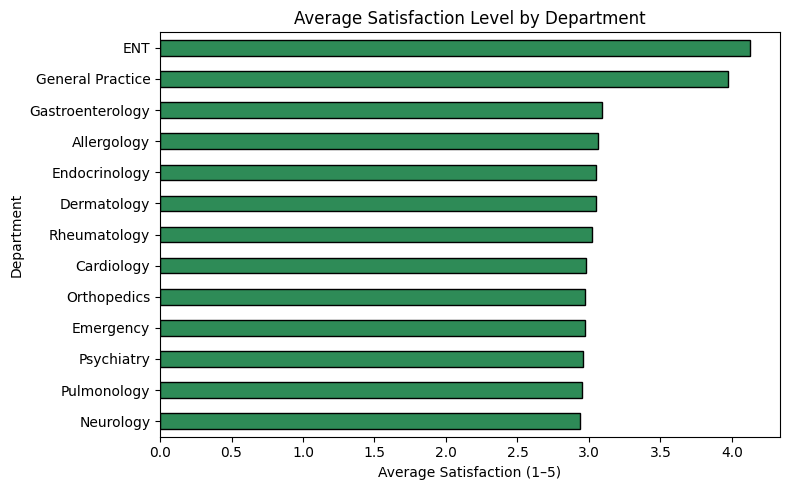

In [45]:
# Satisfaction by department 
dept_sats = df.groupby("Department")["Satisfaction Level"].mean().round(2).sort_values()

print("Average satisfaction per department:")
print(dept_sats)

# Plot
plt.figure(figsize=(8, 5))
dept_sats.plot(kind="barh", edgecolor="black",color='seagreen')
plt.title("Average Satisfaction Level by Department")
plt.xlabel("Average Satisfaction (1–5)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


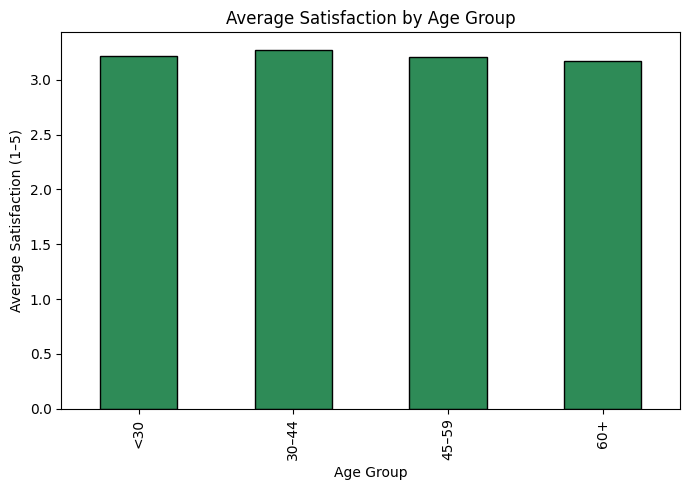

In [46]:
# Patient segment can be any categorization of ABT (Age group, Income group, Gender, Recency buckets, Top department, Visit frequency)

# Satisfaction by Age Group
sats_age_group = df.groupby("Age_Group")["Satisfaction Level"].mean().round(2)

plt.figure(figsize=(7, 5))
sats_age_group.plot(kind="bar", color="seagreen", edgecolor="black")
plt.title("Average Satisfaction by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Satisfaction (1–5)")
plt.tight_layout()
plt.show()

## <font color='#28a745'>3.4 Other Insights and Visualizations

### <font color='#28a745'>3.4.1 Satisfaction vs. Consultation Price

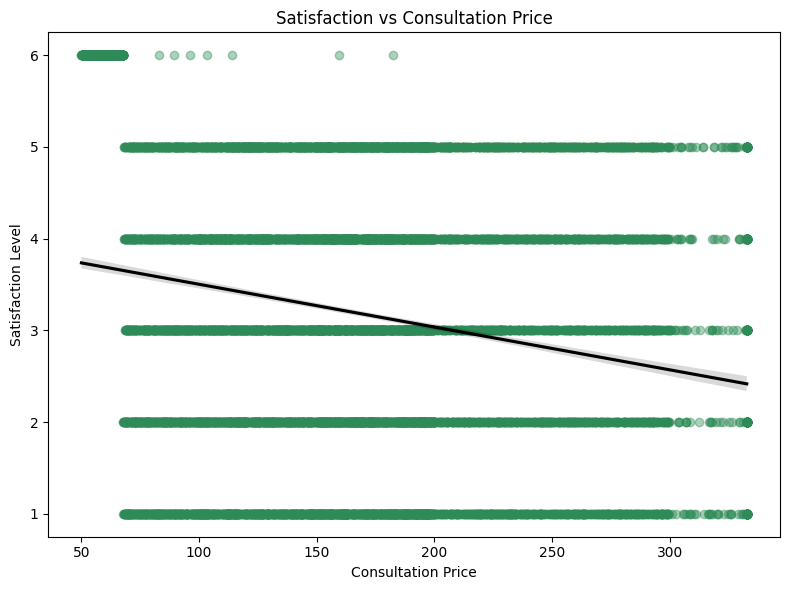

In [47]:
# Satisfaction vs Consultation Price

# 1. Scatter plot with trendline
# This visualization shows the relationship between the continuous variables
# Consultation Price and Satisfaction Level. The trendline helps identify
# potential positive or negative association.

plt.figure(figsize=(8, 6))
sns.regplot(
    data=df,
    x='Consultation Price',
    y='Satisfaction Level',
    scatter_kws={'alpha': 0.4, 'color': 'seagreen'},
    line_kws={'color': 'black'}
)
plt.title("Satisfaction vs Consultation Price") #(Scatter + Trendline)
plt.xlabel("Consultation Price")
plt.ylabel("Satisfaction Level")
plt.tight_layout()
plt.show()

Price bin distribution:
Price_Bin
Low         2500
Mid-Low     2500
Mid-High    2500
High        2500
Name: count, dtype: int64


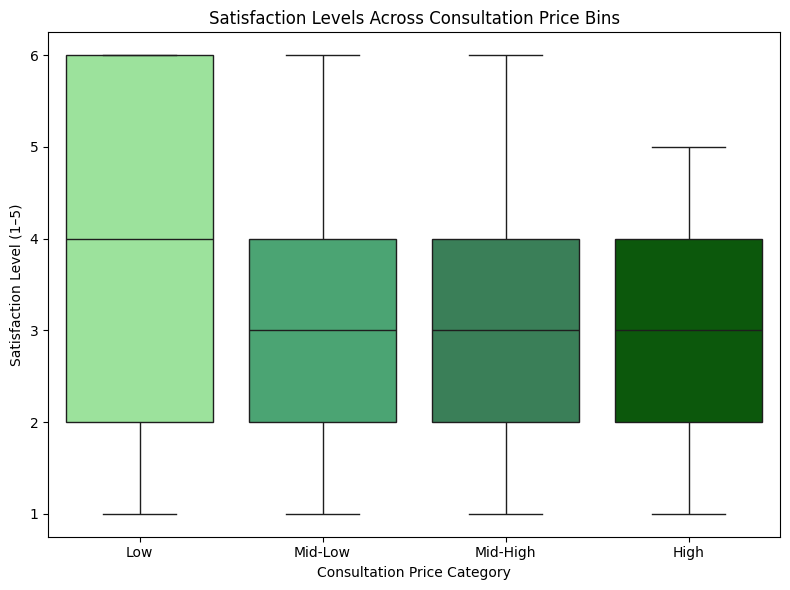

In [48]:
# Satisfaction vs Consultation Price (Boxplot with Price Bins)

# Create price bins (quartiles to keep balanced groups)
df['Price_Bin'] = pd.qcut(
    df['Consultation Price'],
    q=4,
    labels=['Low', 'Mid-Low', 'Mid-High', 'High']
)

print("Price bin distribution:")
print(df['Price_Bin'].value_counts())

# Boxplot: satisfaction distribution per price bin
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df,
    x='Price_Bin',
    y='Satisfaction Level',
    palette=['lightgreen', 'mediumseagreen', 'seagreen', 'darkgreen']
)
plt.title("Satisfaction Levels Across Consultation Price Bins")
plt.xlabel("Consultation Price Category")
plt.ylabel("Satisfaction Level (1–5)")
plt.tight_layout()
plt.show()


### <font color='#28a745'>3.4.2 Satisfaction vs. Number of Visits

Distribution of number of visits:
Num_Visits
9       9
10     50
11     44
12    120
13    234
14    294
15    315
16    544
17    578
18    882
19    741
20    920
21    987
22    748
23    598
24    696
25    675
26    260
27    432
28    280
29    145
30    180
31     93
32     32
34     34
35     70
39     39
Name: count, dtype: int64


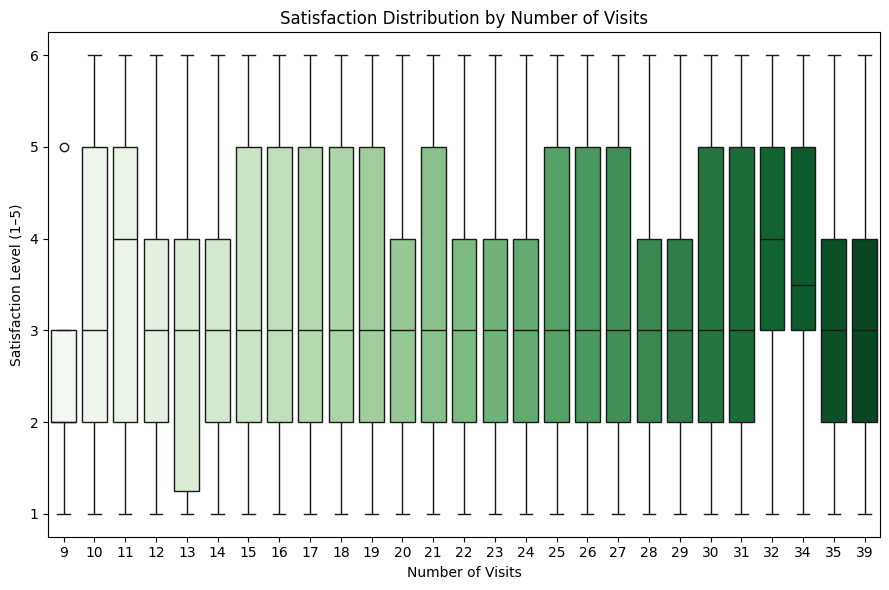

In [49]:
# Satisfaction vs Number of Visits (Boxplot)

# Compute number of visits per patient
visits_per_patient = df.groupby("Patient ID").size().reset_index(name="Num_Visits")

# Merge visits count back to main df
df_visits = df.merge(visits_per_patient, on="Patient ID", how="left")

print("Distribution of number of visits:")
print(df_visits["Num_Visits"].value_counts().sort_index())

# Boxplot showing satisfaction distribution across visit counts
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df_visits,
    x="Num_Visits",
    y="Satisfaction Level",
    palette="Greens"
)
plt.title("Satisfaction Distribution by Number of Visits")
plt.xlabel("Number of Visits")
plt.ylabel("Satisfaction Level (1–5)")
plt.tight_layout()
plt.show()


### <font color='#28a745'>3.4.3 Correlation Heatmap of Key Features

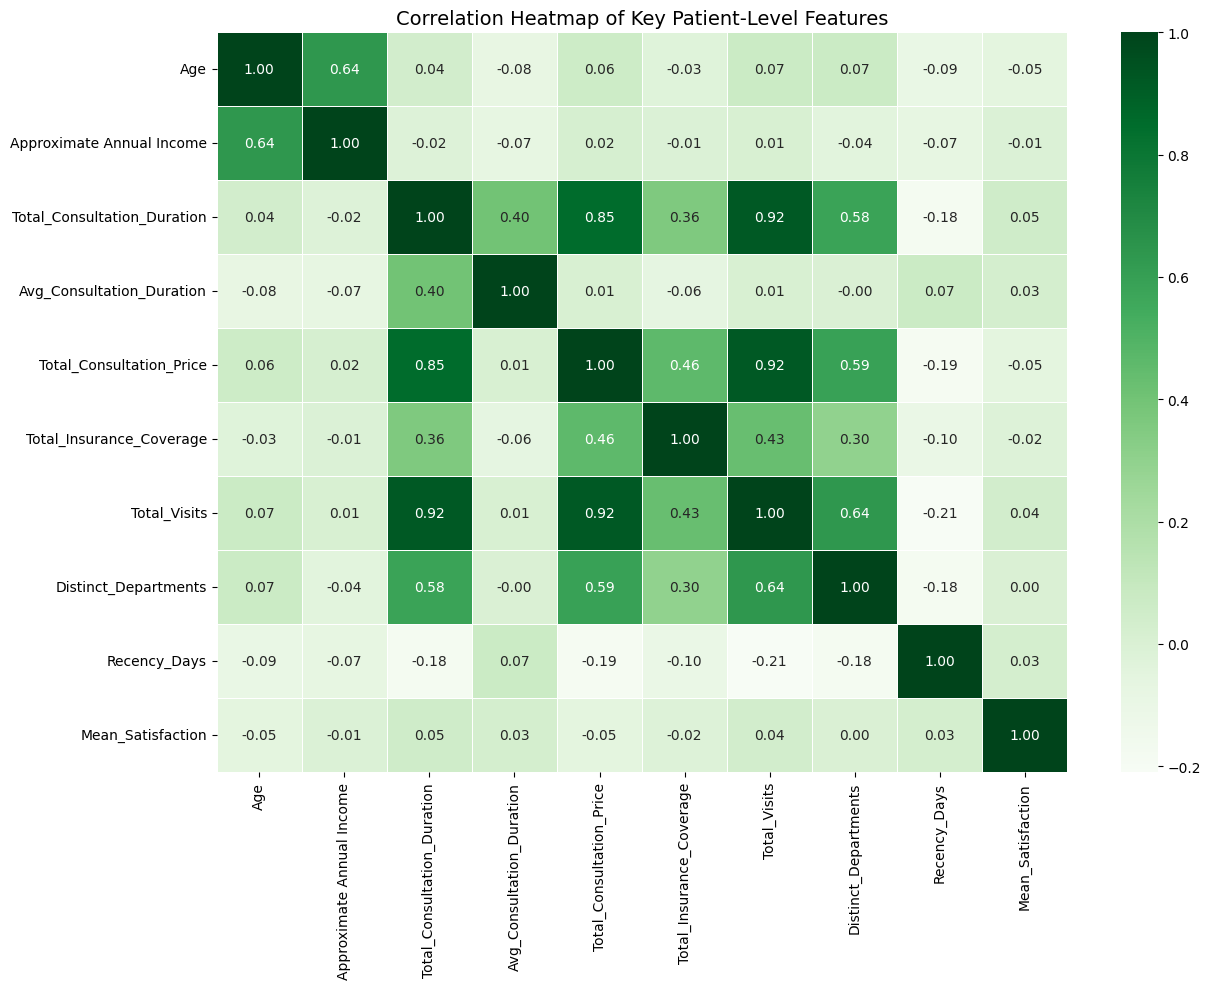

In [52]:
# Correlation Heatmap of Key Features 

key_features = [
    # Demographics
    'Age',
    'Approximate Annual Income',

    # Behavioral and activity metrics
    'Total_Consultation_Duration',
    'Avg_Consultation_Duration',
    'Total_Consultation_Price',
    'Total_Insurance_Coverage',
    'Total_Visits',
    'Distinct_Departments',
    'Recency_Days',

    # Satisfaction
    'Mean_Satisfaction'
]

corr_df = abt[key_features]
corr_matrix = corr_df.corr().round(2)

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='Greens',
    fmt='.2f',
    linewidths=0.5
)
plt.title("Correlation Heatmap of Key Patient-Level Features", fontsize=14)
plt.tight_layout()
plt.show()


# <font color='#28a745'>4 Exportation of ABT csv file

In [53]:
abt.to_csv("ABT_city_hospital.csv", index=False)
print("ABT exported successfully!")

ABT exported successfully!
